# Social Network Analysis Lab
## Christine Lezama

In [4]:
from pathlib import Path
import pandas as pd

dfNode = pd.read_csv(Path.home() / "Downloads" / "marvel_characters_combined.csv")
dfEdge = pd.read_csv(Path.home() / "Downloads" / "ID_co-occurrence.csv")
rawEdges = dfEdge.copy()

print(dfNode.head())
print(dfEdge.head())

        ID        Label Universe
0  1009504  Professor X    x-men
1  1009257      Cyclops    x-men
2  1009362       Iceman    x-men
3  1009159    Archangel    x-men
4  1009175        Beast    x-men
   Character1  Character2
0     1009159     1009163
1     1009159     1009163
2     1009159     1009168
3     1009159     1009168
4     1009159     1009168


In [19]:
pairCounts = rawEdges.groupby(
    ["Character1", "Character2"], as_index=False
).size()

pairCounts = pairCounts.rename(columns={
    "Character1": "from",
    "Character2": "to",
    "size": "weight"
})

dfEdge = pairCounts.copy()
print(dfEdge.head())

      from       to  weight
0  1009159  1009163       2
1  1009159  1009168      12
2  1009159  1009175      26
3  1009159  1009182      14
4  1009159  1009219       6


In [22]:
dfNode["color"] = dfNode["Universe"].map({
    "x-men": "blue",
    "avengers": "red"
})

characters = dfNode.set_index("ID")
dfEdge = pairCounts.copy()

# Save the IDs so we can use them for both lookups.
firstID = dfEdge["from"].copy()
secondID = dfEdge["to"].copy()

dfEdge["fromUniverse"] = firstID.map(characters["Universe"])
dfEdge["toUniverse"] = secondID.map(characters["Universe"])
dfEdge["from"] = firstID.map(characters["Label"])
dfEdge["to"] = secondID.map(characters["Label"])

namedEdges = dfEdge.copy()
print(dfEdge.head())

        from          to  weight fromUniverse toUniverse
0  Archangel      Aurora       2        x-men      x-men
1  Archangel     Banshee      12        x-men      x-men
2  Archangel       Beast      26        x-men      x-men
3  Archangel      Bishop      14        x-men      x-men
4  Archangel  Cannonball       6        x-men      x-men


In [27]:
isCrossover = namedEdges["fromUniverse"] != namedEdges["toUniverse"]
dfEdge = namedEdges[isCrossover].copy()

print(dfEdge.head())
print("Crossover pairs =", len(dfEdge))

         from               to  weight fromUniverse toUniverse
5   Archangel  Captain America       4        x-men   avengers
12  Archangel         Galactus       2        x-men   avengers
16  Archangel         Hercules       2        x-men   avengers
17  Archangel             Hulk       4        x-men   avengers
19  Archangel         Iron Man       2        x-men   avengers
Crossover pairs = 286


In [30]:
import networkx as nx

G = nx.from_pandas_edgelist(
    dfEdge,
    source="from",
    target="to",
    edge_attr=True,
    create_using=nx.DiGraph()
)

print("Nodes =", G.number_of_nodes())
print("Edges =", G.number_of_edges())

Nodes = 53
Edges = 286


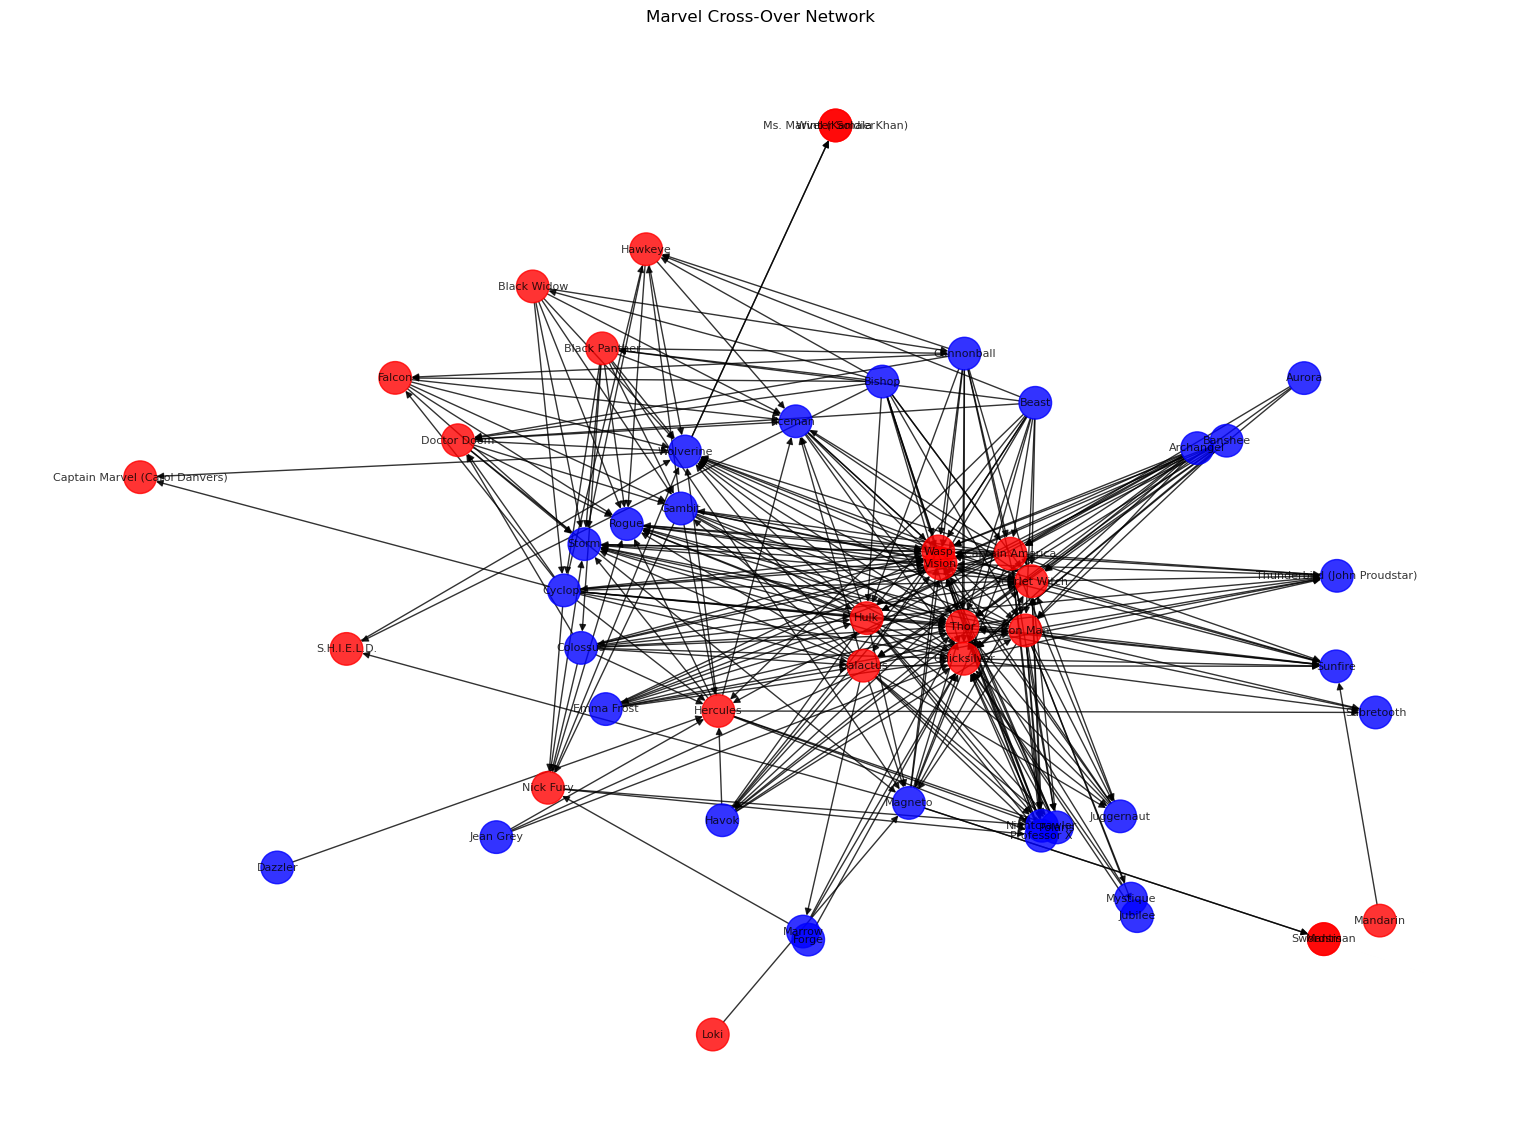

In [32]:
import matplotlib.pyplot as plt

colors = dfNode.set_index("Label")["color"]
nodeColors = [colors[name] for name in G.nodes()]
pos = nx.kamada_kawai_layout(G, weight=None)

plt.figure(figsize=(15, 11))
nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=nodeColors,
    node_size=550,
    font_size=8,
    arrows=True,
    arrowsize=10,
    alpha=0.8
)
plt.title("Marvel Cross-Over Network")
plt.show()

Blue nodes represent X-Men characters, and red nodes represent Avengers characters. Each arrow connects two characters from different universes who appeared together in at least one comic. The graph has 53 characters and 286 crossover links.

In [35]:
print(f"Network density = {nx.density(G):.2%}")

degree = pd.Series(nx.degree_centrality(G))
closeness = pd.Series(nx.closeness_centrality(G))

print("\nTop 5 by degree centrality")
print(degree.nlargest(5).round(4))

print("\nTop 5 by closeness centrality")
print(closeness.nlargest(5).round(4))

Network density = 10.38%

Top 5 by degree centrality
Quicksilver        0.5385
Thor               0.5000
Iron Man           0.4615
Captain America    0.4231
Hulk               0.4038
dtype: float64

Top 5 by closeness centrality
Thor           0.5385
Wolverine      0.5377
Vision         0.4899
Quicksilver    0.4808
Wasp           0.4773
dtype: float64


The network density is 10.38%, meaning about one in ten possible directed links is present. Quicksilver had the highest degree centrality (0.5385), followed by Thor (0.5000), Iron Man (0.4615), and Captain America (0.4231). Hulk, Scarlet Witch, and Vision tied for fifth at 0.4038. Thor had the highest closeness centrality (0.5385), followed by Wolverine (0.5377), Vision (0.4899), Quicksilver (0.4808), and Wasp (0.4773).

In [38]:
pairs = [
    ("Winter Soldier", "Magneto"),
    ("Magneto", "Winter Soldier")
]

for start, end in pairs:
    if nx.has_path(G, start, end):
        path = nx.shortest_path(G, start, end)
        print("Path =", " -> ".join(path))
        print("Distance =", len(path) - 1)
    else:
        print(f"No directed path from {start} to {end}.")

No directed path from Winter Soldier to Magneto.
Path = Magneto -> Quicksilver -> Wolverine -> Winter Soldier
Distance = 3


Following the arrows, there’s no path from Winter Soldier to Magneto. Going the other way, the shortest path is Magneto, Quicksilver,  Wolverine, Winter Soldier, which takes 3 links.